In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
import nltk
from wordcloud import WordCloud
import re
from nltk.corpus import stopwords
from nltk.tokenize import TweetTokenizer
from nltk.stem import WordNetLemmatizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import cross_val_predict
import tensorflow as tf
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score



# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/Dataset/Data.xlsx'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Reading Dataset 

In [3]:
df = pd.read_excel("C:/Users/Yups/OneDrive/Desktop/New-project/FG-USA(S2021027011)/Dataset/Data.xlsx")

In [4]:
df.head()

,Unnamed: 0,Product_ID,Customer_Name,Customer_ID,Date,Rating,Spam(1) and Not Spam(0),Reviews,Sentiment,Features
0,0,TE111EL1KXNGWNAFAMZ,itzmr7,6702,2019-11-09,1,0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota']
1,1,MI543EL02ACXSNAFAMZ,Afridi,396,2016-11-21,5,0,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']"
2,2,MI543EL02ACXSNAFAMZ,Muhammed,3710,2018-10-22,2,0,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']"
3,3,TE111EL1KXNGWNAFAMZ,Ghazanfar,1860,2017-10-06,3,0,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',..."
4,4,SO638EL103OUWNAFAMZ,Murtaza iqbal,3778,2017-08-31,4,0,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle..."


In [5]:
df= df[['Reviews','Sentiment','Features']]

In [6]:
df.head()

,Reviews,Sentiment,Features
0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota']
1,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']"
2,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']"
3,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',..."
4,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle..."


# Preprocessing dataset
- Removing ursl (http\S+|www\S+|https\S+)
- Remove Mentions ('\@\w+|\#)
- Removing Stopwords
- Remove Special character and number

Note: Lemetization, Stamming, are not possible for Roman Urdu Dataset 


In [7]:
# stop words source   
# https://github.com/haseebelahi/roman-urdu-stopwords

In [8]:
# Preprocessing fucntion

def preprocess_tweet(tweet):
    # Convert to lowercase
    tweet = tweet.lower()
    
    # Remove URLs
    tweet = re.sub(r"http\S+|www\S+|https\S+", '', tweet, flags=re.MULTILINE)
    
    # Remove mentions
    tweet = re.sub(r'\@\w+|\#', '', tweet)
    
    # Tokenize tweet
    tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)
    tokens = tokenizer.tokenize(tweet)
    
    # Remove stopwords
    #stop_words = set(stopwords.words('/kaggle/input/my-roman-urdu/stop.txt'))
    #tokens = [token for token in tokens if token not in stop_words]
   
    # Remove special characters and numbers
    tokens = [re.sub(r'[^a-zA-Z]', '', token) for token in tokens]
    
 
    # Join tokens back into a single string
    processed_tweet = ' '.join(tokens)
    
    return processed_tweet

# Apply preprocessing to the 'Reviews' column
df['Processed_Reviews'] = df['Reviews'].apply(preprocess_tweet)
df.head()

,Reviews,Sentiment,Features,Processed_Reviews
0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota'],mil gya hai acha hai aur toota howa b nai hai
1,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']",aram sy pocket may aa jta hai aur quality b ac...
2,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']",sb sy achi chez apki customer service bhot ach...
3,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',...",back cover acha hai sai cuts hai aur soft b ha...
4,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle...",shru may may thumb grip k khalif thi kyu k ext...


In [9]:
df= df[['Processed_Reviews','Sentiment','Features']]
df.head()

,Processed_Reviews,Sentiment,Features
0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota']
1,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']"
2,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']"
3,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',..."
4,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle..."


Fine-grained sentiment analysis attempts to extract sentiment holders, targets and polar ex- pressions and resolve the relationship between them, but progress has been hampered by the difficulty of annotation.

In [10]:
df.head()

,Processed_Reviews,Sentiment,Features
0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota']
1,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']"
2,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']"
3,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',..."
4,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle..."


In [11]:
df.rename(columns={'Processed_Reviews': 'Reviews'}, inplace=True)

In [12]:
df.head()

,Reviews,Sentiment,Features
0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota']
1,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']"
2,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']"
3,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',..."
4,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle..."


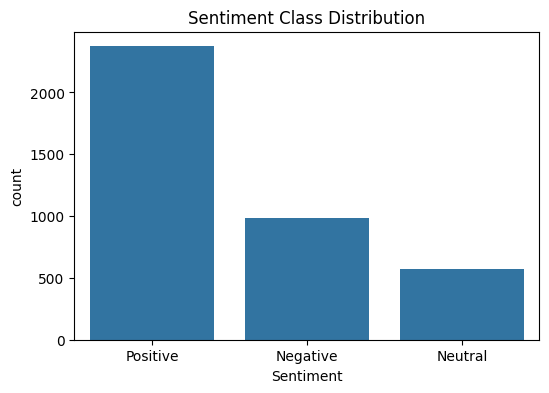

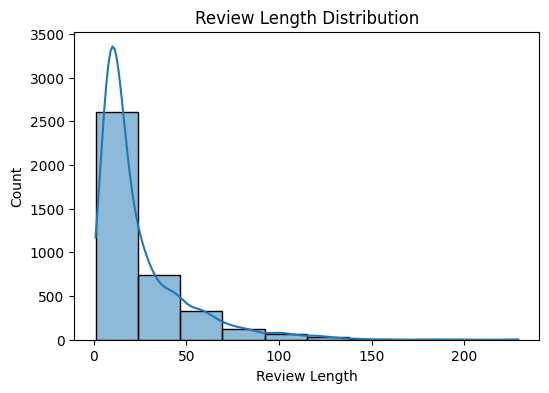

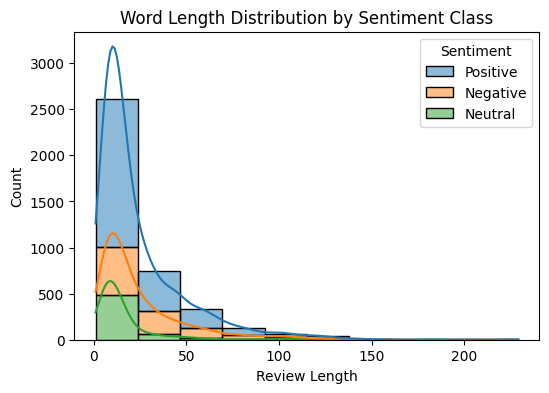

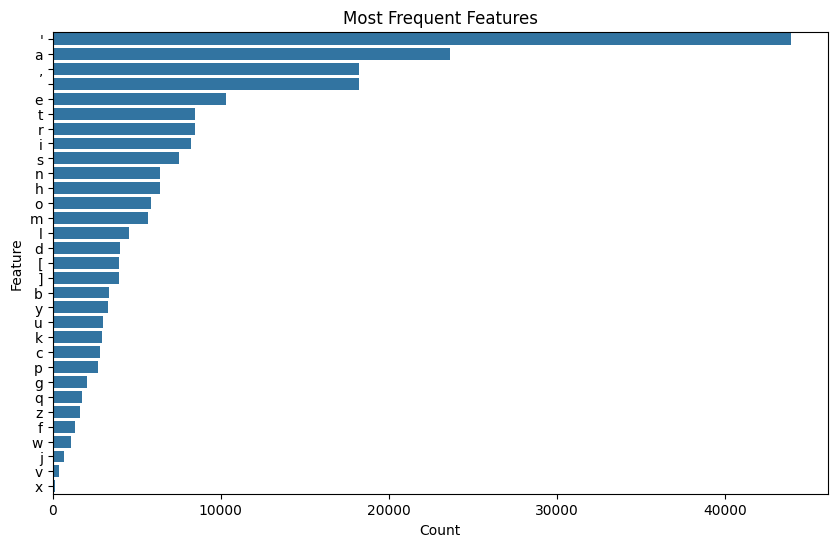

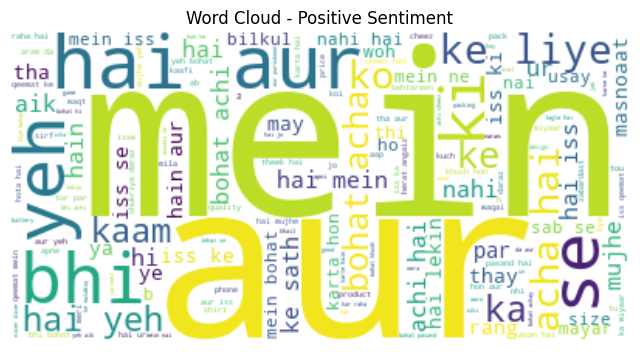

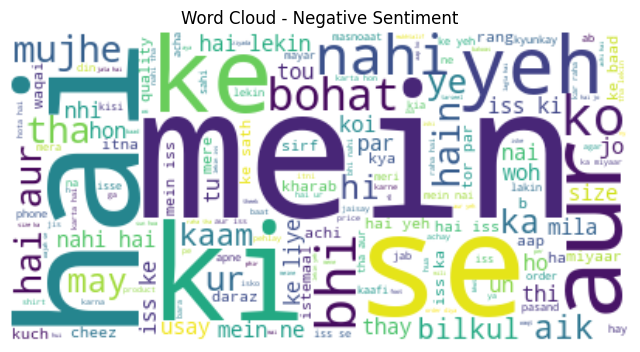

In [13]:
# Distribution of sentiment classes
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sentiment')
plt.title('Sentiment Class Distribution')
plt.show()

# Length of reviews
df['Review Length'] = df['Reviews'].apply(lambda x: len(x.split()))
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x='Review Length', bins=10, kde=True)
plt.title('Review Length Distribution')
plt.show()

# Length of words in each sentiment class
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x='Review Length', hue='Sentiment', multiple='stack', bins=10, kde=True)
plt.title('Word Length Distribution by Sentiment Class')
plt.show()

# Most frequent features
all_features = [feature for features in df['Features'] for feature in features]
feature_counts = pd.Series(all_features).value_counts().sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=feature_counts.values, y=feature_counts.index)
plt.title('Most Frequent Features')
plt.xlabel('Count')
plt.ylabel('Feature')
plt.show()


# Word clouds for positive and negative sentiment classes
positive_reviews = ' '.join(df[df['Sentiment'] == 'Positive']['Reviews'])
negative_reviews = ' '.join(df[df['Sentiment'] == 'Negative']['Reviews'])

# Positive sentiment word cloud
plt.figure(figsize=(8, 6))
wordcloud_positive = WordCloud(background_color='white').generate(positive_reviews)
plt.imshow(wordcloud_positive, interpolation='bilinear')
plt.title('Word Cloud - Positive Sentiment')
plt.axis('off')
plt.show()

# Negative sentiment word cloud
plt.figure(figsize=(8, 6))
wordcloud_negative = WordCloud(background_color='white').generate(negative_reviews)
plt.imshow(wordcloud_negative, interpolation='bilinear')
plt.title('Word Cloud - Negative Sentiment')
plt.axis('off')
plt.show()

# Targeted Features distribution 

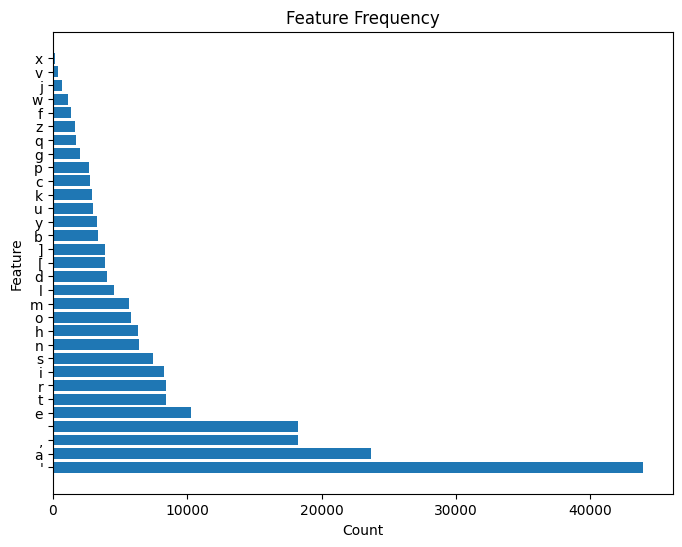

In [14]:
# Extract the targeted features
all_features = [feature for features in df['Features'] for feature in features]

# Count the occurrences of each feature
feature_counts = pd.Series(all_features).value_counts()

# Plot the feature frequency
plt.figure(figsize=(8, 6))
plt.barh(feature_counts.index, feature_counts.values)
plt.xlabel('Count')
plt.ylabel('Feature')
plt.title('Feature Frequency')
plt.show()

In [15]:
df['Reviews'][1]

'aram sy pocket may aa jta hai aur quality b achi hai'

In [16]:
#Combine the sentence and target features as the text to be used for analysis:
df['Text'] = df['Reviews'] + ' [' + df['Features'].apply(lambda x: ', '.join(x)) + ']'

In [17]:
df.head()

,Reviews,Sentiment,Features,Review Length,Text
0,mil gya hai acha hai aur toota howa b nai hai,Positive,['toota'],11,mil gya hai acha hai aur toota howa b nai hai ...
1,aram sy pocket may aa jta hai aur quality b ac...,Positive,"['aram', 'pocket', 'quality']",12,aram sy pocket may aa jta hai aur quality b ac...
2,sb sy achi chez apki customer service bhot ach...,Positive,"['customer', 'products', 'orignal']",15,sb sy achi chez apki customer service bhot ach...
3,back cover acha hai sai cuts hai aur soft b ha...,Positive,"['back', 'cover', 'cuts', 'soft', 'protector',...",46,back cover acha hai sai cuts hai aur soft b ha...
4,shru may may thumb grip k khalif thi kyu k ext...,Negative,"['thumb', 'grip', 'chezy', 'stock', 'controlle...",83,shru may may thumb grip k khalif thi kyu k ext...


In [18]:
df['Text'][1]

"aram sy pocket may aa jta hai aur quality b achi hai [[, ', a, r, a, m, ', ,,  , ', p, o, c, k, e, t, ', ,,  , ', q, u, a, l, i, t, y, ', ]]"

In [19]:
corpus = df['Text']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(corpus)
y = df['Sentiment']

In [20]:
df['Text'][1]

"aram sy pocket may aa jta hai aur quality b achi hai [[, ', a, r, a, m, ', ,,  , ', p, o, c, k, e, t, ', ,,  , ', q, u, a, l, i, t, y, ', ]]"

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
svm = SVC()
svm.fit(X_train, y_train)

SVC()

In [23]:
y_pred = svm.predict(X_test)

In [24]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Negative       0.72      0.53      0.61       202
     Neutral       0.65      0.12      0.20       128
    Positive       0.71      0.95      0.81       455

    accuracy                           0.71       785
   macro avg       0.69      0.53      0.54       785
weighted avg       0.70      0.71      0.66       785



# Complete Code

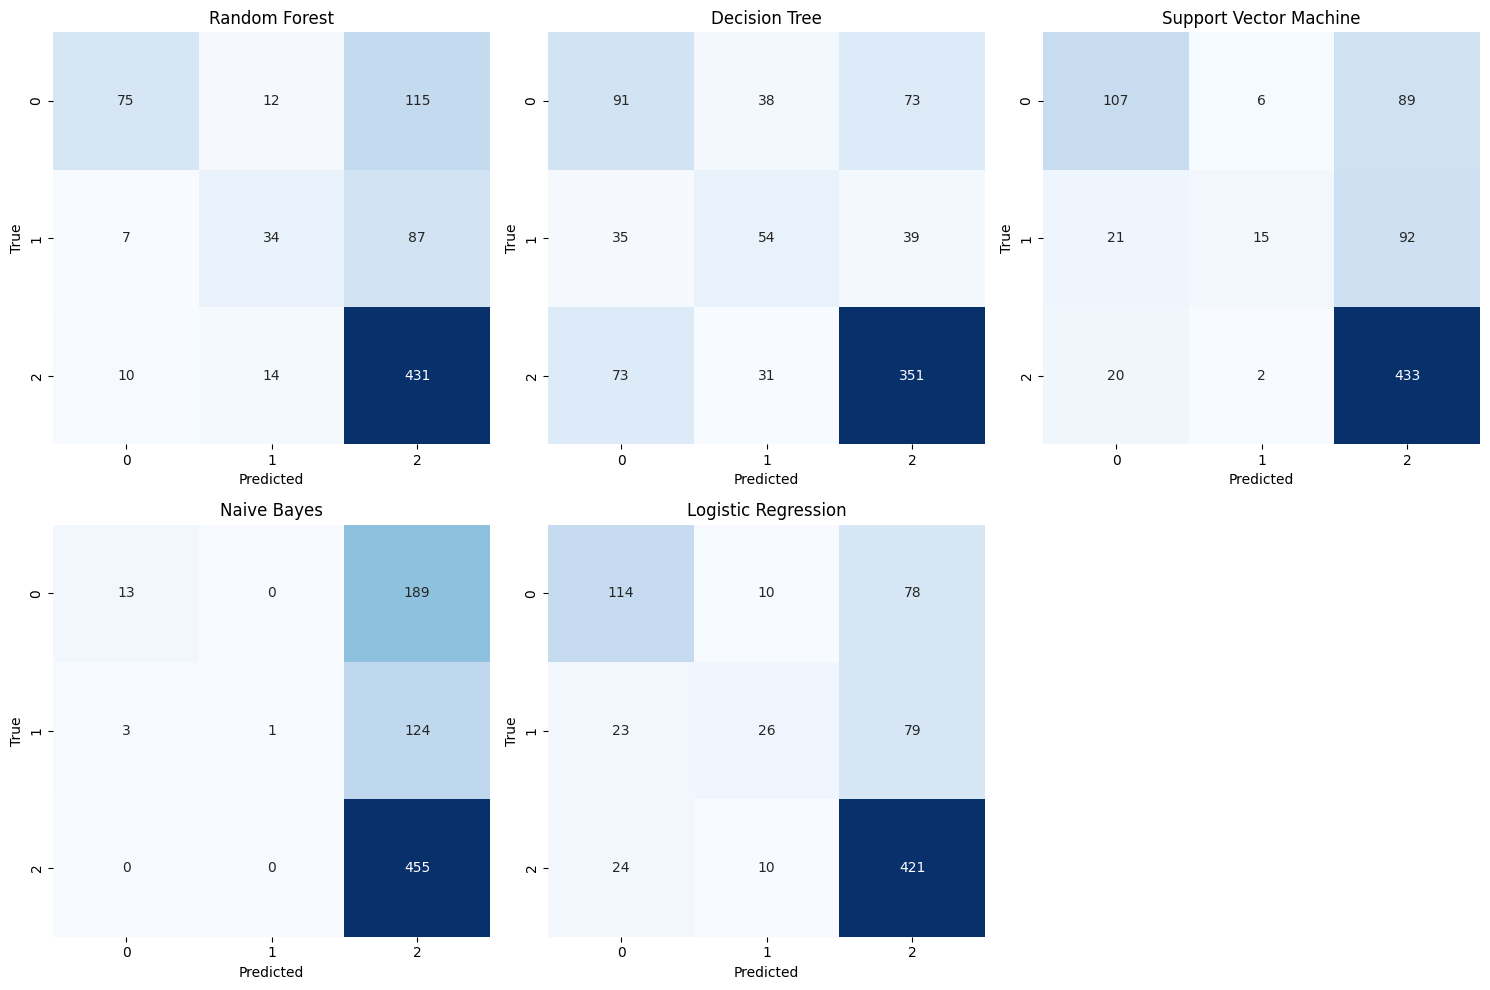

Classification Report for Random Forest:
              precision    recall  f1-score   support

    Negative       0.82      0.37      0.51       202
     Neutral       0.57      0.27      0.36       128
    Positive       0.68      0.95      0.79       455

    accuracy                           0.69       785
   macro avg       0.69      0.53      0.55       785
weighted avg       0.70      0.69      0.65       785


Classification Report for Decision Tree:
              precision    recall  f1-score   support

    Negative       0.46      0.45      0.45       202
     Neutral       0.44      0.42      0.43       128
    Positive       0.76      0.77      0.76       455

    accuracy                           0.63       785
   macro avg       0.55      0.55      0.55       785
weighted avg       0.63      0.63      0.63       785


Classification Report for Support Vector Machine:
              precision    recall  f1-score   support

    Negative       0.72      0.53      0.61      

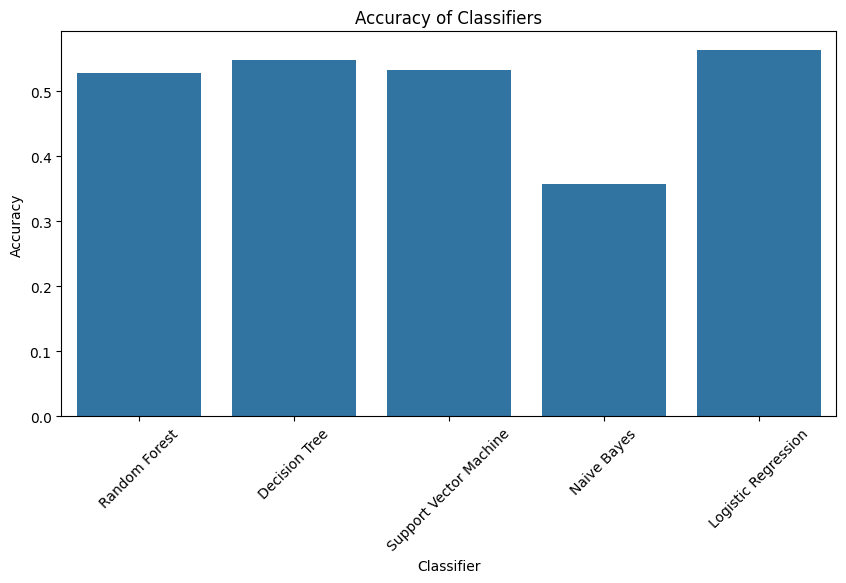

In [25]:
'''df = pd.read_excel("/kaggle/input/daraz-roman-urdu-reviews/Daraz Labelled Review Dataset with Sentiments and Features.xlsx")
df = df[['Reviews', 'Sentiment', 'Features']]

# Combine the sentence and target features as the text to be used for analysis:
df['Text'] = df['Reviews'] + ' [' + df['Features'].apply(lambda x: ', '.join(x)) + ']'

corpus = df['Text']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(corpus)
y = df['Sentiment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)'''

# Initialize classifiers
classifiers = {
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC(),
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression()
}

results = {}

# Train and evaluate each classifier
for classifier_name, classifier in classifiers.items():
    classifier.fit(X_train, y_train)
    y_pred = classifier.predict(X_test)
    classification_rep = classification_report(y_test, y_pred)
    confusion_mat = confusion_matrix(y_test, y_pred)
    results[classifier_name] = {'classification_report': classification_rep, 'confusion_matrix': confusion_mat}

# Plot confusion matrices
plt.figure(figsize=(15, 10))
for i, (classifier_name, result) in enumerate(results.items()):
    plt.subplot(2, 3, i+1)
    sns.heatmap(result['confusion_matrix'], annot=True, cmap='Blues', fmt='d', cbar=False)
    plt.title(classifier_name)
    plt.xlabel('Predicted')
    plt.ylabel('True')

plt.tight_layout()
plt.show()

# Print classification reports
for classifier_name, result in results.items():
    print(f"Classification Report for {classifier_name}:")
    print(result['classification_report'])
    print()

# Overall results plot
plt.figure(figsize=(10, 5))
accuracy = [np.mean(result['confusion_matrix'].diagonal() / result['confusion_matrix'].sum(axis=1)) for result in results.values()]
sns.barplot(x=list(classifiers.keys()), y=accuracy)
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('Accuracy of Classifiers')
plt.xticks(rotation=45)
plt.show()

# Cross-Validation

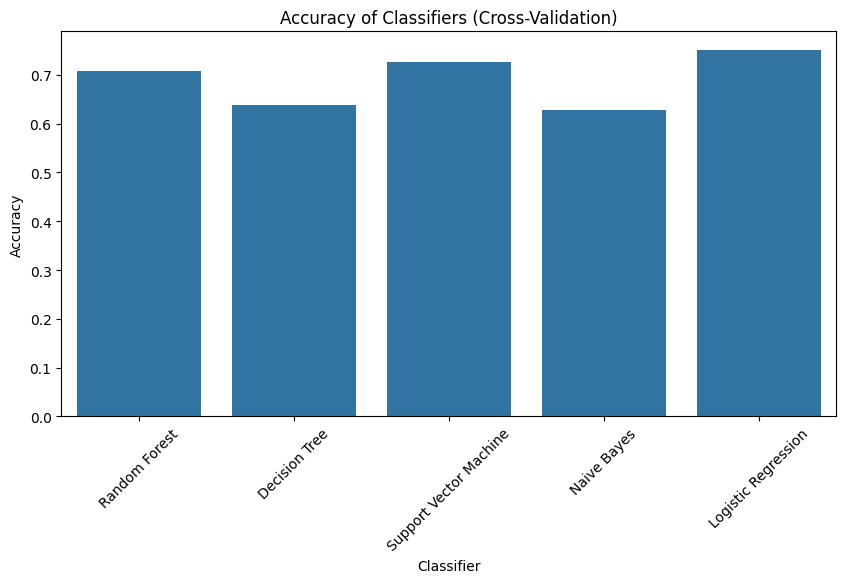

Classifier: Random Forest
Accuracy Scores: [0.70229008 0.71246819 0.75318066 0.74234694 0.7244898  0.7244898
 0.65561224 0.68367347 0.71173469 0.67857143]
Mean Accuracy: 0.708885729864465

Classifier: Decision Tree
Accuracy Scores: [0.65903308 0.60305344 0.67430025 0.67091837 0.66836735 0.70153061
 0.59438776 0.64030612 0.59693878 0.56887755]
Mean Accuracy: 0.6377713299060083

Classifier: Support Vector Machine
Accuracy Scores: [0.72519084 0.70737913 0.74554707 0.74744898 0.76785714 0.72704082
 0.71683673 0.72193878 0.71173469 0.69642857]
Mean Accuracy: 0.7267402762631769

Classifier: Naive Bayes
Accuracy Scores: [0.62086514 0.62086514 0.64631043 0.64540816 0.63010204 0.63010204
 0.62244898 0.625      0.62755102 0.61734694]
Mean Accuracy: 0.6285999896141663

Classifier: Logistic Regression
Accuracy Scores: [0.76844784 0.72519084 0.77608142 0.78316327 0.78826531 0.75
 0.72959184 0.75765306 0.72193878 0.71683673]
Mean Accuracy: 0.7517169081373007



In [26]:
# Initialize classifiers
classifiers = {
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC(),
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression()
}

results = {}

# Train and evaluate each classifier using cross-validation
for classifier_name, classifier in classifiers.items():
    scores = cross_val_score(classifier, X, y, cv=10, scoring='accuracy')
    results[classifier_name] = scores

# Overall results plot
plt.figure(figsize=(10, 5))
mean_accuracy = [np.mean(scores) for scores in results.values()]
sns.barplot(x=list(classifiers.keys()), y=mean_accuracy)
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('Accuracy of Classifiers (Cross-Validation)')
plt.xticks(rotation=45)
plt.show()

# Detailed results
for classifier_name, scores in results.items():
    print(f"Classifier: {classifier_name}")
    print(f"Accuracy Scores: {scores}")
    print(f"Mean Accuracy: {np.mean(scores)}")
    print()

# Removing low Accurecy class CV-1 to CV-10 Models Performance

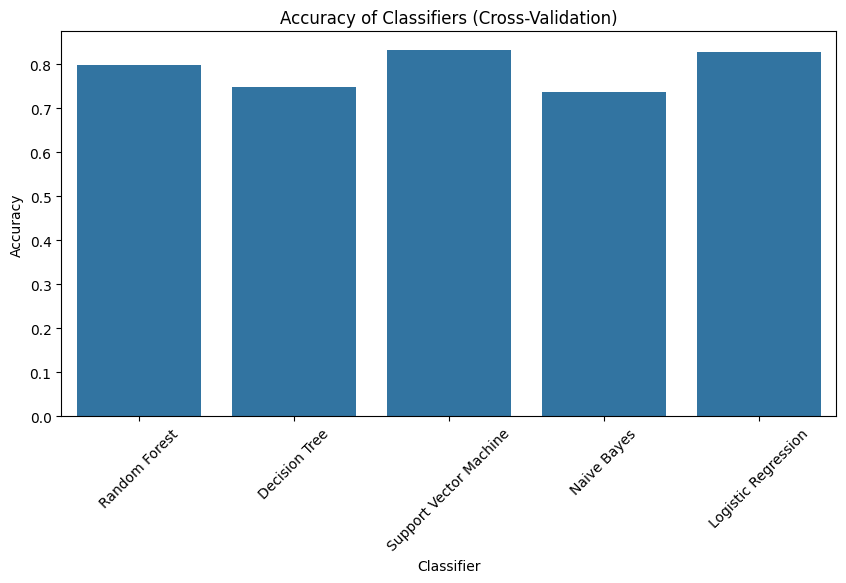

Classifier: Random Forest
Accuracy Scores: [0.79761905 0.79166667 0.83928571 0.82440476 0.79166667 0.8
 0.77910448 0.8        0.79104478 0.76119403]
Mean Accuracy: 0.7975986140724947

Classifier: Decision Tree
Accuracy Scores: [0.75       0.69345238 0.72619048 0.75       0.76488095 0.8238806
 0.7641791  0.77313433 0.74029851 0.70746269]
Mean Accuracy: 0.7493479033404407

Classifier: Support Vector Machine
Accuracy Scores: [0.83035714 0.81845238 0.85119048 0.86607143 0.85119048 0.83283582
 0.82686567 0.8358209  0.8238806  0.79701493]
Mean Accuracy: 0.8333679815209665

Classifier: Naive Bayes
Accuracy Scores: [0.72916667 0.73511905 0.75297619 0.75       0.73809524 0.74029851
 0.73134328 0.73432836 0.74626866 0.72537313]
Mean Accuracy: 0.738296908315565

Classifier: Logistic Regression
Accuracy Scores: [0.83333333 0.80357143 0.85416667 0.86309524 0.8452381  0.8238806
 0.8238806  0.82686567 0.81492537 0.79104478]
Mean Accuracy: 0.8280001776830135



In [27]:
# Filter out only "Positive" and "Negative" classes
df = df[df['Sentiment'].isin(['Positive', 'Negative'])]

# Combine the sentence and target features as the text to be used for analysis:
df['Text'] = df['Reviews'] + ' [' + df['Features'].apply(lambda x: ', '.join(x)) + ']'

corpus = df['Text']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(corpus)
y = df['Sentiment']

# Initialize classifiers
classifiers = {
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC(),
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression()
}

results = {}

# Train and evaluate each classifier using cross-validation
for classifier_name, classifier in classifiers.items():
    scores = cross_val_score(classifier, X, y, cv=10, scoring='accuracy')
    results[classifier_name] = scores

# Overall results plot
plt.figure(figsize=(10, 5))
mean_accuracy = [np.mean(scores) for scores in results.values()]
sns.barplot(x=list(classifiers.keys()), y=mean_accuracy)
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('Accuracy of Classifiers (Cross-Validation)')
plt.xticks(rotation=45)
plt.show()

# Detailed results
for classifier_name, scores in results.items():
    print(f"Classifier: {classifier_name}")
    print(f"Accuracy Scores: {scores}")
    print(f"Mean Accuracy: {np.mean(scores)}")
    print()

# Models Performance with removing Low Accuracy class 

Classifier: Random Forest
              precision    recall  f1-score   support

    Negative       0.85      0.40      0.54       983
    Positive       0.80      0.97      0.87      2372

    accuracy                           0.80      3355
   macro avg       0.82      0.68      0.71      3355
weighted avg       0.81      0.80      0.78      3355



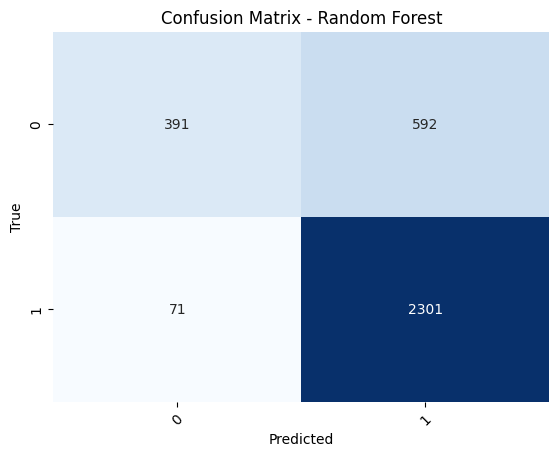

Classifier: Decision Tree
              precision    recall  f1-score   support

    Negative       0.59      0.56      0.57       983
    Positive       0.82      0.84      0.83      2372

    accuracy                           0.75      3355
   macro avg       0.70      0.70      0.70      3355
weighted avg       0.75      0.75      0.75      3355



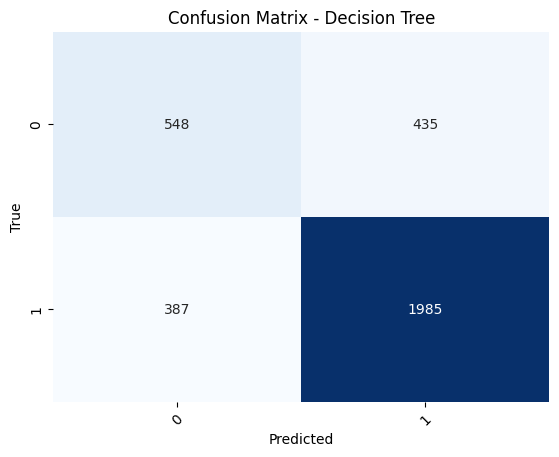

Classifier: Support Vector Machine
              precision    recall  f1-score   support

    Negative       0.82      0.55      0.66       983
    Positive       0.84      0.95      0.89      2372

    accuracy                           0.83      3355
   macro avg       0.83      0.75      0.77      3355
weighted avg       0.83      0.83      0.82      3355



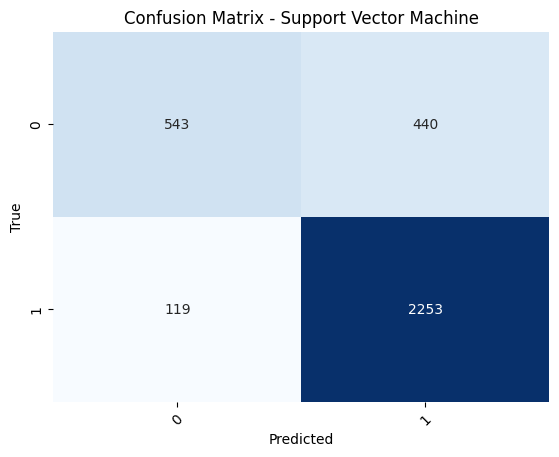

Classifier: Naive Bayes
              precision    recall  f1-score   support

    Negative       0.94      0.11      0.20       983
    Positive       0.73      1.00      0.84      2372

    accuracy                           0.74      3355
   macro avg       0.84      0.56      0.52      3355
weighted avg       0.79      0.74      0.66      3355



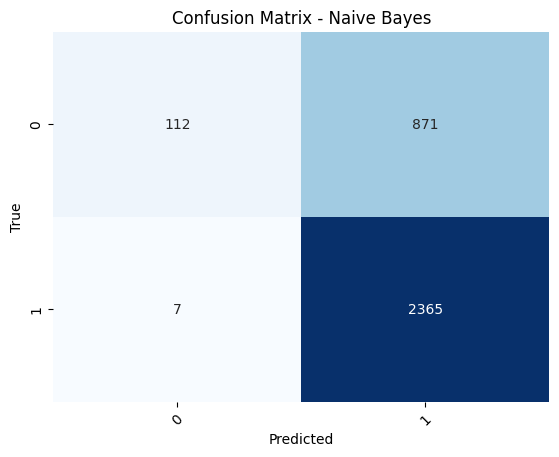

Classifier: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.83      0.52      0.64       983
    Positive       0.83      0.95      0.89      2372

    accuracy                           0.83      3355
   macro avg       0.83      0.74      0.76      3355
weighted avg       0.83      0.83      0.81      3355



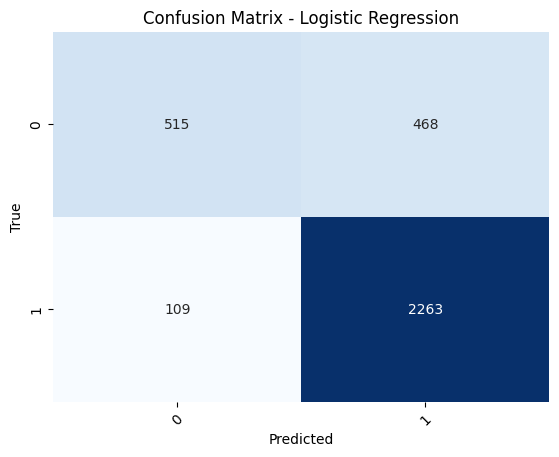

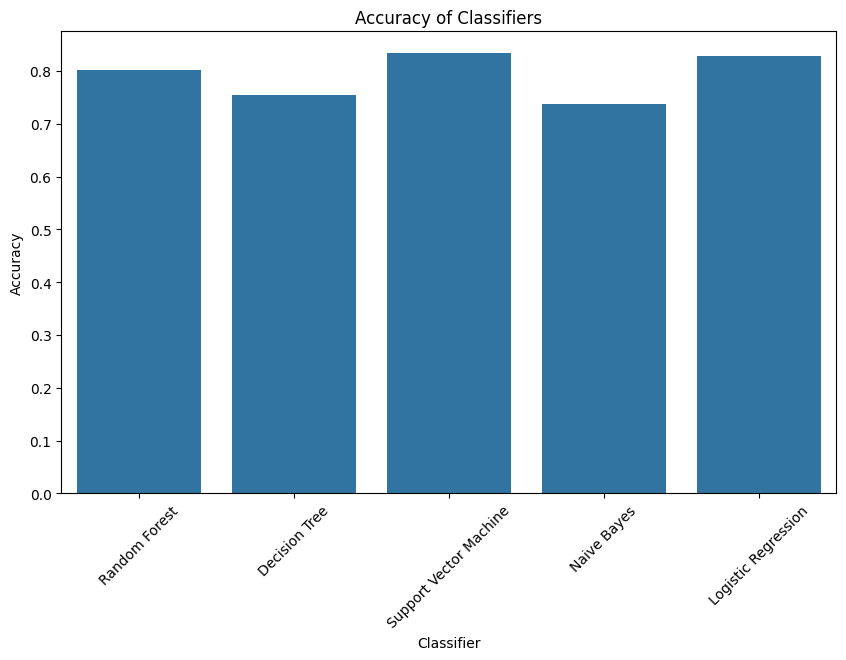

In [28]:
# Initialize classifiers
classifiers = {
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC(),
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression()
}

results = {}

# Train and evaluate each classifier using cross-validation
for classifier_name, classifier in classifiers.items():
    y_pred = cross_val_predict(classifier, X, y, cv=10)
    classification_rep = classification_report(y, y_pred)
    confusion_mat = confusion_matrix(y, y_pred)
    accuracy = np.mean(y_pred == y)
    results[classifier_name] = {'classification_report': classification_rep, 'confusion_matrix': confusion_mat, 'accuracy': accuracy}

# Print classification report and plot confusion matrix for each algorithm
for classifier_name, result in results.items():
    print(f"Classifier: {classifier_name}")
    print(result['classification_report'])

    plt.figure()
    sns.heatmap(result['confusion_matrix'], annot=True, cmap='Blues', fmt='d', cbar=False)
    plt.title(f'Confusion Matrix - {classifier_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.xticks(rotation=45)
    plt.show()

# Plot accuracy of classifiers
plt.figure(figsize=(10, 6))
accuracy = [result['accuracy'] for result in results.values()]
sns.barplot(x=list(classifiers.keys()), y=accuracy)
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('Accuracy of Classifiers')
plt.xticks(rotation=45)
plt.show()

# Deep learning with RNN(Features) + LSTM(Learning) With Hyperparameter Tuning 

c:\Users\Yups\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 56s 604ms/step - accuracy: 0.6733 - loss: 0.6194 - val_accuracy: 0.7079 - val_loss: 0.5686
Epoch 2/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 87s 669ms/step - accuracy: 0.7096 - loss: 0.5497 - val_accuracy: 0.7228 - val_loss: 0.4872
Epoch 3/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 48s 577ms/step - accuracy: 0.7876 - loss: 0.4366 - val_accuracy: 0.7914 - val_loss: 0.4773
Epoch 4/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 60s 701ms/step - accuracy: 0.8656 - loss: 0.3672 - val_accuracy: 0.8122 - val_loss: 0.4736
Epoch 5/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 59s 439ms/step - accuracy: 0.8749 - loss: 0.3676 - val_accuracy: 0.6945 - val_loss: 0.6004
Epoch 6/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 38s 456ms/step - accuracy: 0.7746 - loss: 0.5134 - val_accuracy: 0.7094 - val_loss: 0.5837
Epoch 7/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 38s 453ms/step - accuracy: 0.7380 - loss: 0.5203 - val_accuracy: 0.7839 - val_loss: 0.4917
Epoch 8/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 42s 499ms/step - accuracy: 0.8941 - loss: 0.3430 - val_accu

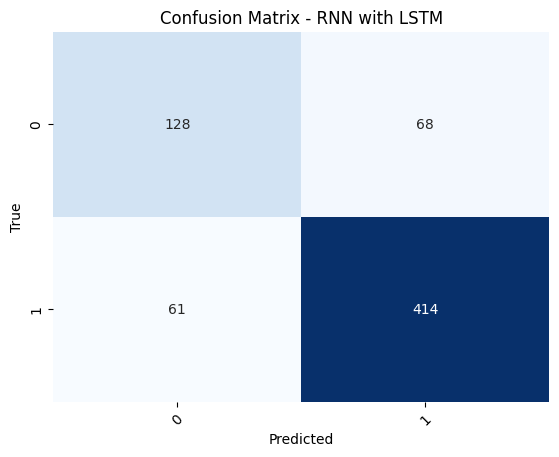

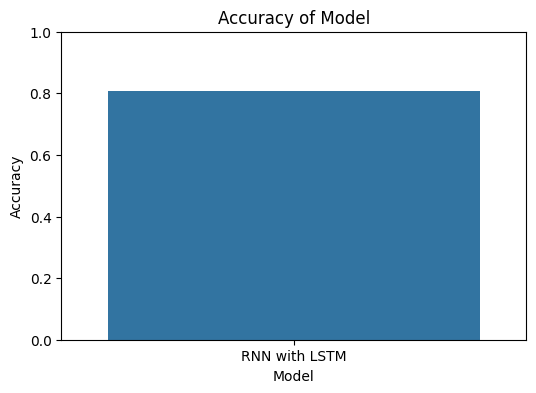

In [29]:
# Convert the class labels to numeric values
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Tokenize the text data
tokenizer = Tokenizer()
tokenizer.fit_on_texts(corpus)
sequences = tokenizer.texts_to_sequences(corpus)

# Pad the sequences to have equal length
max_sequence_length = max(len(seq) for seq in sequences)
X = pad_sequences(sequences, maxlen=max_sequence_length)

# Split the dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the RNN model with LSTM layers
embedding_dim = 100
hidden_units = 64
num_classes = len(label_encoder.classes_)

model = Sequential()
model.add(Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=embedding_dim, input_length=max_sequence_length))
model.add(LSTM(hidden_units))
model.add(Dense(num_classes, activation='softmax'))

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

# Evaluate the model
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
classification_rep = classification_report(y_test, y_pred)
confusion_mat = confusion_matrix(y_test, y_pred)
accuracy = np.mean(y_pred == y_test)

# Print classification report and plot confusion matrix
print("RNN with LSTM")
print(classification_rep)
plt.figure()
sns.heatmap(confusion_mat, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.title('Confusion Matrix - RNN with LSTM')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45)
plt.show()

# Plot accuracy
plt.figure(figsize=(6, 4))
sns.barplot(x=['RNN with LSTM'], y=[accuracy])
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Accuracy of Model')
plt.ylim([0, 1])
plt.show()

Epoch 1/10


c:\Users\Yups\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


84/84 ━━━━━━━━━━━━━━━━━━━━ 57s 615ms/step - accuracy: 0.6801 - loss: 0.6257 - val_accuracy: 0.7079 - val_loss: 0.5740
Epoch 2/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 46s 549ms/step - accuracy: 0.7151 - loss: 0.5514 - val_accuracy: 0.6364 - val_loss: 0.5947
Epoch 3/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 81s 542ms/step - accuracy: 0.7815 - loss: 0.4663 - val_accuracy: 0.7586 - val_loss: 0.5357
Epoch 4/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 78s 492ms/step - accuracy: 0.8224 - loss: 0.4479 - val_accuracy: 0.7660 - val_loss: 0.4882
Epoch 5/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 41s 488ms/step - accuracy: 0.8534 - loss: 0.3869 - val_accuracy: 0.8048 - val_loss: 0.4736
Epoch 6/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 49s 586ms/step - accuracy: 0.8742 - loss: 0.3736 - val_accuracy: 0.8003 - val_loss: 0.4726
Epoch 7/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 46s 546ms/step - accuracy: 0.8867 - loss: 0.3441 - val_accuracy: 0.8122 - val_loss: 0.4706
Epoch 8/10
84/84 ━━━━━━━━━━━━━━━━━━━━ 76s 476ms/step - accuracy: 0.8994 - loss: 0.3049 - val_accuracy: 0.807

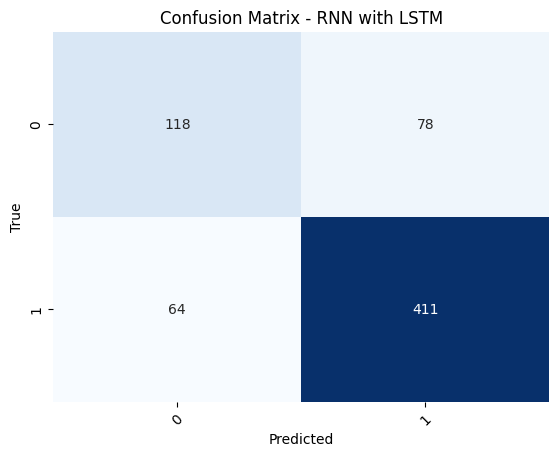

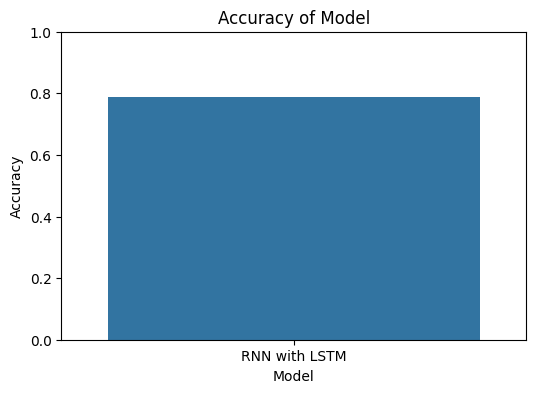

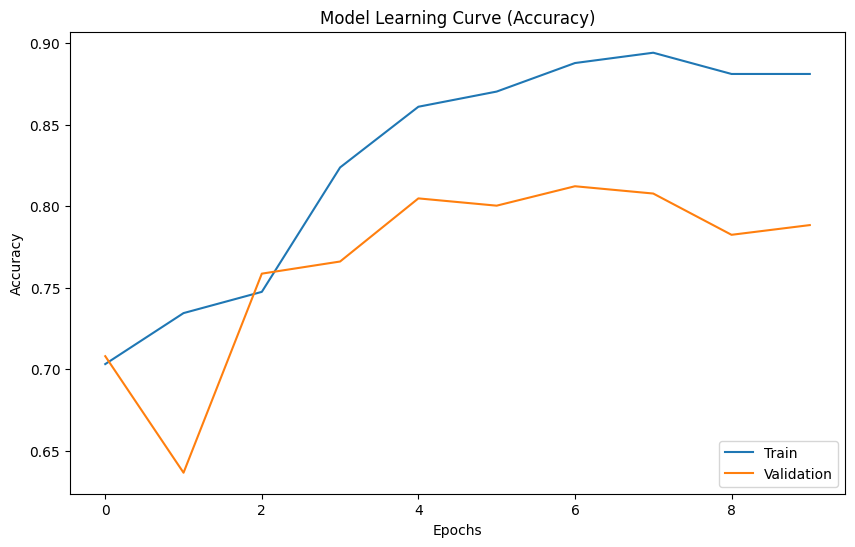

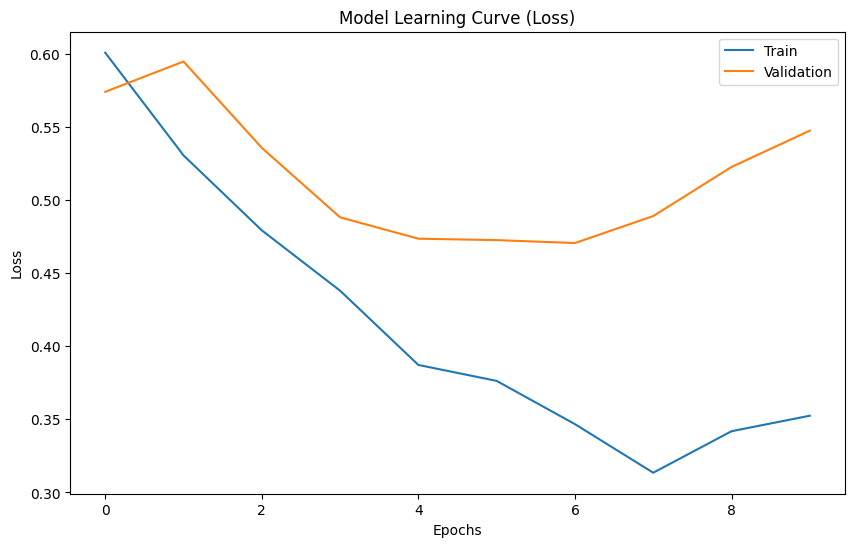

In [30]:
# Convert the class labels to numeric values
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# Tokenize the text data
tokenizer = Tokenizer()
tokenizer.fit_on_texts(corpus)
sequences = tokenizer.texts_to_sequences(corpus)

# Pad the sequences to have equal length
max_sequence_length = max(len(seq) for seq in sequences)
X = pad_sequences(sequences, maxlen=max_sequence_length)

# Split the dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the RNN model with LSTM layers
embedding_dim = 100
hidden_units = 64
num_classes = len(label_encoder.classes_)

model = Sequential()
model.add(Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=embedding_dim, input_length=max_sequence_length))
model.add(LSTM(hidden_units))
model.add(Dense(num_classes, activation='softmax'))

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

# Evaluate the model
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
classification_rep = classification_report(y_test, y_pred)
confusion_mat = confusion_matrix(y_test, y_pred)
accuracy = np.mean(y_pred == y_test)

# Print classification report and plot confusion matrix
print("RNN with LSTM")
print(classification_rep)
plt.figure()
sns.heatmap(confusion_mat, annot=True, cmap='Blues', fmt='d', cbar=False)
plt.title('Confusion Matrix - RNN with LSTM')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.xticks(rotation=45)
plt.show()

# Plot accuracy
plt.figure(figsize=(6, 4))
sns.barplot(x=['RNN with LSTM'], y=[accuracy])
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Accuracy of Model')
plt.ylim([0, 1])
plt.show()

# Plot learning curve (accuracy)
plt.figure(figsize=(10, 6))
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Learning Curve (Accuracy)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()

# Plot learning curve (loss)
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Learning Curve (Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

# RNN with LSTM with Hyper parameter tuning 

# GUI (Run in .py Use Vscode to Run)

In [32]:
import gradio as gr
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
import os

# Global variables
classifiers = {
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC(),
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression()
}
trained_classifiers = {}


def train_classifiers():
    # Check if the file exists
    file_path = "C:/Users/Yups/OneDrive/Desktop/New-project/FG-USA(S2021027011)/Dataset/Data.xlsx"
    if not os.path.exists(file_path):
        raise FileNotFoundError(f"The file {file_path} does not exist. Please check the file path.")

    # Read and preprocess the data
    df = pd.read_excel(file_path)
    df = df[['Reviews', 'Sentiment', 'Features']]
    df = df[df['Sentiment'].isin(['Positive', 'Negative'])]
    df['Text'] = df['Reviews'] + ' [' + df['Features'].apply(lambda x: ', '.join(x)) + ']'
    corpus = df['Text']

    # Vectorize the input data
    vectorizer = TfidfVectorizer()
    X = vectorizer.fit_transform(corpus)
    y = df['Sentiment']

    # Train and store each classifier
    for classifier_name, classifier in classifiers.items():
        trained_classifier = classifier.fit(X, y)
        trained_classifiers[classifier_name] = {'classifier': trained_classifier, 'vectorizer': vectorizer}


def classify_text(text, algorithm):
    if algorithm in trained_classifiers:
        classifier = trained_classifiers[algorithm]['classifier']
        vectorizer = trained_classifiers[algorithm]['vectorizer']

        # Vectorize the input text
        input_vector = vectorizer.transform([text])

        # Predict the sentiment
        predicted_sentiment = classifier.predict(input_vector)[0]

        # Get the features used for classification
        feature_names = vectorizer.get_feature_names_out()
        used_features = [feature_names[idx] for idx in input_vector.nonzero()[1]][:2]  # Get top 2 features

        return f"Predicted Sentiment: {predicted_sentiment}", f"Target Features:\n{', '.join(used_features)}"
    else:
        return "Algorithm not found", ""


# Train the classifiers
try:
    train_classifiers()
except FileNotFoundError as e:
    print(e)
    exit()

# Create the Gradio interface
input_text = gr.components.Textbox(label="Input Text")
algorithm = gr.components.Dropdown(choices=list(classifiers.keys()), label="Select Algorithm")
outputs = [gr.components.Textbox(label="Predicted Sentiment"), gr.components.Textbox(label="Target Features")]

interface = gr.Interface(
    fn=classify_text,
    inputs=[input_text, algorithm],
    outputs=outputs,
    title="Sentiment Analysis with Multiple Classifiers",
    description="Enter text and select an algorithm to predict sentiment and extract features."
)

# Launch the interface
interface.launch()

* Running on local URL:  http://127.0.0.1:7862

To create a public link, set `share=True` in `launch()`.
